# Condition-Aware LLPS Prediction — Model Training and Evaluation

Reproduces all reported results starting from `LLPSDB_v2_model_dataset.csv`.

**Structure**
1. Setup and data load
2. Sequence clustering and leakage-proof grouping (regenerates `Cluster_ID`)
3. Sample weights for condition-grid expansion
4. Regime C split + leakage assertions
5. Baselines and the sequence / environment ablation
6. Optimism of a naive random split
7. Hyperparameter tuning (regime C) and held-out evaluation
8. The three generalization regimes
9. Regime A: tuning, held-out test, calibration, SHAP

Total runtime ~15 min (the two hyperparameter searches dominate).

## 1. Setup and data load

In [ ]:
!pip install xgboost shap parasail biopython scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 51.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 58.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [biopython]


In [ ]:
# !pip install xgboost shap parasail biopython scikit-learn
import warnings, json, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, f1_score,
                             matthews_corrcoef, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
import parasail, shap
print("libraries loaded")

libraries loaded


In [ ]:
CSV = "LLPSDB_v2_model_dataset.csv"      # <-- path to your dataset
df = pd.read_csv(CSV)
print("shape:", df.shape)

ENV = ['temperature_C','protein_conc_uM','pH','PEG_300_1k_pct','PEG_3k_6k_pct','PEG_8k_20k_pct',
       'Ficoll_pct','Dextran_le40k_pct','Dextran_ge70k_pct','MgCl2_mM','NaCl_mM','KCl_mM','glycerol_pct']
SEQ = [c for c in df.columns if c not in ENV + ['PSID','Protein_ID','Sequence','Label']]
COLS = SEQ + ENV
print(f"sequence features: {len(SEQ)}   environment features: {len(ENV)}   total: {len(COLS)}")
print("label counts:", df.Label.value_counts().to_dict())
print("missing feature values:", int(df[COLS].isna().sum().sum()))

shape: (20719, 60)
sequence features: 43   environment features: 13   total: 56
label counts: {1: 11660, 0: 9059}
missing feature values: 0


## 2. Sequence clustering and leakage-proof grouping

`Cluster_ID` is not present in the exported CSV, so it is regenerated here. This is a greedy
length-descending clustering equivalent to `mmseqs easy-cluster --min-seq-id X -c 0.90 --cov-mode 1`
(cov-mode 1 = the alignment must cover >=90% of the member sequence), using Smith-Waterman
alignment with BLOSUM62.

At 30% identity this yields **189 clusters**, closely matching the 191 reported from MMseqs2.

Clusters alone are **not sufficient** for leakage control: different constructs of the same
protein can fall into different clusters. Groups are therefore the connected components of the
bipartite graph linking sequence clusters to `Protein_ID`.

In [ ]:
def cluster_sequences(seq_list, min_id, min_cov=0.90):
    """Greedy clustering; returns {sequence: representative_sequence}."""
    mat = parasail.blosum62
    seqs = sorted(seq_list, key=len, reverse=True)
    reps, assign = [], {}
    for s in seqs:
        L, placed = len(s), None
        for r in reps:
            if len(r) < min_cov * L:          # coverage of member cannot be met
                continue
            tr = parasail.sw_trace_striped_16(s, r, 11, 1, mat).traceback
            aln = len(tr.query)
            if not aln:
                continue
            ident = sum(1 for a, b in zip(tr.query, tr.ref) if a == b) / aln
            cov   = sum(1 for a in tr.query if a != '-') / L
            if ident >= min_id and cov >= min_cov:
                placed = r; break
        if placed is None:
            reps.append(s); assign[s] = s
        else:
            assign[s] = placed
    return assign

uniq = df["Sequence"].dropna().unique().tolist()
print("unique sequences:", len(uniq))
t0 = time.time()
clu30 = cluster_sequences(uniq, 0.30)
clu50 = cluster_sequences(uniq, 0.50)
print(f"clusters @30% identity: {len(set(clu30.values()))}   (MMseqs2 reported 191)")
print(f"clusters @50% identity: {len(set(clu50.values()))}   ({time.time()-t0:.0f}s)")

unique sequences: 815
clusters @30% identity: 189   (MMseqs2 reported 191)
clusters @50% identity: 202   (30s)


In [ ]:
def add_groups(d, assign, col):
    cl = pd.factorize(d["Sequence"].map(assign))[0]
    pr = pd.factorize(d["Protein_ID"])[0]
    ncl = cl.max() + 1
    A = sp.coo_matrix((np.ones(len(d)), (cl, ncl + pr)), shape=(ncl + pr.max() + 1,) * 2)
    d[col] = connected_components(A + A.T, directed=False)[1][cl]
    return d

df = add_groups(df, clu50, "Group")      # primary grouping
df = add_groups(df, clu30, "Group30")    # stricter, used as a sensitivity check

for col, lab in [("Group", "50% identity"), ("Group30", "30% identity")]:
    sz = df.groupby(col).size().sort_values(ascending=False)
    print(f"{lab}: {df[col].nunique():4d} groups, largest = {sz.iloc[0]:6,} rows "
          f"({100*sz.iloc[0]/len(df):.1f}% of data)")

50% identity:  179 groups, largest =  3,006 rows (14.5% of data)
30% identity:  153 groups, largest =  9,683 rows (46.7% of data)


At 30% identity, homology chaining collapses 47% of all rows into a single group, which makes
5-fold grouped CV unusable. The 50% grouping is therefore used as primary and the 30% grouping
is reported as a sensitivity check (Section 7).

## 3. Sample weights for condition-grid expansion

One experimental record (`PSID`) expands into up to 176 condition rows that all inherit the same
label. Unweighted training lets a handful of records dominate the loss, so each row is weighted
by `1 / (rows for its PSID)` — one experimental observation contributes one unit of evidence.
All metrics below are likewise PSID-weighted.

In [ ]:
df["w_psid"] = 1.0 / df.groupby("PSID")["Label"].transform("size")
n = df.groupby("PSID").size()
print(f"PSIDs: {len(n):,}   rows per PSID: mean {n.mean():.1f}, max {n.max()}")

PSIDs: 2,626   rows per PSID: mean 7.9, max 176


## 4. Regime C split and leakage assertions

Held-out test = whole homology groups, so no sequence, protein or experimental record is shared
with training.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)
tr_idx, te_idx = next(iter(sgkf.split(df, df.Label, groups=df.Group)))
df["split"] = "train"; df.loc[df.index[te_idx], "split"] = "test"
tr, te = df[df.split == "train"], df[df.split == "test"]

for nm, d in [("train", tr), ("test", te)]:
    print(f"{nm:5s} rows={len(d):6,}  groups={d.Group.nunique():4d}  proteins={d.Protein_ID.nunique():4d}"
          f"  PSIDs={d.PSID.nunique():5d}  seqs={d.Sequence.nunique():4d}  pos_rate={d.Label.mean():.3f}")

print("\nleakage checks (shared between train and test):")
for k in ["Group", "Protein_ID", "PSID", "Sequence"]:
    o = len(set(tr[k]) & set(te[k])); print(f"  {k:11s} {o}")
    assert o == 0, f"LEAK on {k}"
print("  ALL CLEAN")

train rows=16,711  groups= 136  proteins= 189  PSIDs= 2040  seqs= 588  pos_rate=0.565
test  rows= 4,008  groups=  43  proteins=  60  PSIDs=  586  seqs= 227  pos_rate=0.554

leakage checks (shared between train and test):
  Group       0
  Protein_ID  0
  PSID        0
  Sequence    0
  ALL CLEAN


## 5. Baselines and the sequence / environment ablation

Grouped 5-fold CV **inside the training set only**. Both weighting schemes are compared.

In [ ]:
trr = tr.reset_index(drop=True)
SETS = {"sequence only (43)": SEQ, "environment only (13)": ENV, "sequence + environment (56)": COLS}

def cv_eval(cols, model_fn, weighted):
    sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1); out = []
    for a, b in sg.split(trr, trr.Label, groups=trr.Group):
        Xa, Xb = trr.loc[a, cols], trr.loc[b, cols]
        ya, yb = trr.loc[a, "Label"], trr.loc[b, "Label"]
        wa, wb = trr.loc[a, "w_psid"], trr.loc[b, "w_psid"]
        m = model_fn()
        if weighted:
            key = (m.steps[-1][0] + "__sample_weight") if isinstance(m, Pipeline) else "sample_weight"
            m.fit(Xa, ya, **{key: wa})
        else:
            m.fit(Xa, ya)
        p = m.predict_proba(Xb)[:, 1]
        if yb.nunique() < 2: continue
        out.append([roc_auc_score(yb, p, sample_weight=wb),
                    average_precision_score(yb, p, sample_weight=wb),
                    roc_auc_score(yb, p)])
    return np.array(out)

MODELS = {
 "logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0)),
 "XGBoost (default)":   lambda: XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                            tree_method="hist", n_jobs=8, random_state=0),
}
base = (trr.Label * trr.w_psid).sum() / trr.w_psid.sum()
print(f"majority-class baseline: ROC-AUC 0.500   PR-AUC {base:.3f}\n")
print(f"{'model':22s} {'features':28s} {'wt':4s} {'ROC-AUC':>18s} {'PR-AUC':>18s}")
print("-" * 95)
for mn, mf in MODELS.items():
    for sn, cols in SETS.items():
        for wt in [False, True]:
            r = cv_eval(cols, mf, wt)
            print(f"{mn:22s} {sn:28s} {'yes' if wt else 'no':4s} "
                  f"{r[:,0].mean():9.3f} ± {r[:,0].std():.3f} {r[:,1].mean():11.3f} ± {r[:,1].std():.3f}")

majority-class baseline: ROC-AUC 0.500   PR-AUC 0.623

model                  features                     wt              ROC-AUC             PR-AUC
-----------------------------------------------------------------------------------------------


logistic regression    sequence only (43)           no       0.547 ± 0.058       0.662 ± 0.059


logistic regression    sequence only (43)           yes      0.534 ± 0.038       0.656 ± 0.051
logistic regression    environment only (13)        no       0.566 ± 0.035       0.689 ± 0.051


logistic regression    environment only (13)        yes      0.566 ± 0.040       0.698 ± 0.064


logistic regression    sequence + environment (56)  no       0.580 ± 0.034       0.692 ± 0.052


logistic regression    sequence + environment (56)  yes      0.595 ± 0.035       0.703 ± 0.049


... (2 outputs left out)

XGBoost (default)      environment only (13)        no       0.575 ± 0.039       0.709 ± 0.038


XGBoost (default)      environment only (13)        yes      0.596 ± 0.035       0.718 ± 0.040


XGBoost (default)      sequence + environment (56)  no       0.581 ± 0.042       0.700 ± 0.046


XGBoost (default)      sequence + environment (56)  yes      0.596 ± 0.063       0.710 ± 0.024


Sequence features alone sit at chance on unseen families, and adding them to the environmental
features changes nothing. PSID weighting helps slightly and is used from here on.

## 6. Optimism of a naive random split

Identical model, identical data — only the split differs.

In [ ]:
X, y, g, w = trr[COLS], trr.Label, trr.Group, trr.w_psid
mk = lambda: XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                           colsample_bytree=0.8, eval_metric="logloss", tree_method="hist",
                           n_jobs=8, random_state=0)

def run(splitter, groups):
    a = []
    for i, j in splitter.split(X, y, groups=groups):
        m = mk(); m.fit(X.iloc[i], y.iloc[i], sample_weight=w.iloc[i])
        p = m.predict_proba(X.iloc[j])[:, 1]
        a.append([roc_auc_score(y.iloc[j], p, sample_weight=w.iloc[j]),
                  average_precision_score(y.iloc[j], p, sample_weight=w.iloc[j])])
    return np.array(a)

leaky   = run(StratifiedKFold(5, shuffle=True, random_state=1), None)
grouped = run(StratifiedGroupKFold(5, shuffle=True, random_state=1), g)
print(f"random row split (leaky)      ROC-AUC {leaky[:,0].mean():.3f} ± {leaky[:,0].std():.3f}   PR-AUC {leaky[:,1].mean():.3f}")
print(f"homology-aware grouped split  ROC-AUC {grouped[:,0].mean():.3f} ± {grouped[:,0].std():.3f}   PR-AUC {grouped[:,1].mean():.3f}")
print(f"inflation: +{leaky[:,0].mean()-grouped[:,0].mean():.3f} ROC-AUC")

random row split (leaky)      ROC-AUC 0.853 ± 0.027   PR-AUC 0.888
homology-aware grouped split  ROC-AUC 0.596 ± 0.063   PR-AUC 0.710
inflation: +0.256 ROC-AUC


## 7. Hyperparameter tuning (regime C) and held-out evaluation

~3 min.

In [ ]:
param = dict(max_depth=randint(2, 9), learning_rate=loguniform(0.01, 0.3),
             n_estimators=randint(150, 900), min_child_weight=loguniform(1, 60),
             subsample=uniform(0.5, 0.5), colsample_bytree=uniform(0.4, 0.6),
             reg_lambda=loguniform(0.5, 50), reg_alpha=loguniform(1e-3, 5), gamma=loguniform(1e-3, 5))
search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=4, random_state=0),
    param, n_iter=60, scoring="roc_auc",
    cv=StratifiedGroupKFold(5, shuffle=True, random_state=1), n_jobs=2, random_state=0, refit=False)
t0 = time.time(); search.fit(X, y, groups=g, sample_weight=w)
print(f"best grouped-CV ROC-AUC: {search.best_score_:.3f}   ({time.time()-t0:.0f}s)")
bp_C = {k: (int(v) if k in ("max_depth", "n_estimators") else float(v))
        for k, v in search.best_params_.items()}
print(bp_C)

best grouped-CV ROC-AUC: 0.597   (202s)
{'colsample_bytree': 0.5950283374050115, 'gamma': 0.0013871853702313369, 'learning_rate': 0.08647681628389767, 'max_depth': 8, 'min_child_weight': 1.5186269678300874, 'n_estimators': 789, 'reg_alpha': 0.22338999810764232, 'reg_lambda': 48.929315441602455, 'subsample': 0.7909251647192672}


In [ ]:
m = XGBClassifier(**bp_C, eval_metric="logloss", tree_method="hist", n_jobs=8, random_state=0)
m.fit(tr[COLS], tr.Label, sample_weight=tr.w_psid)
p = m.predict_proba(te[COLS])[:, 1]
print("REGIME C — HELD-OUT TEST")
print(f"  ROC-AUC (PSID-weighted) {roc_auc_score(te.Label, p, sample_weight=te.w_psid):.3f}")
print(f"  PR-AUC  (PSID-weighted) {average_precision_score(te.Label, p, sample_weight=te.w_psid):.3f}")
print(f"  Brier {brier_score_loss(te.Label, p):.3f}  (baseline {te.Label.mean()*(1-te.Label.mean()):.3f})")

# sensitivity: stricter 30% grouping
sg = StratifiedGroupKFold(5, shuffle=True, random_state=1); a = []
for i, j in sg.split(df, df.Label, groups=df.Group30):
    d1, d2 = df.iloc[i], df.iloc[j]
    mm = XGBClassifier(**bp_C, eval_metric="logloss", tree_method="hist", n_jobs=8, random_state=0)
    mm.fit(d1[COLS], d1.Label, sample_weight=d1.w_psid)
    pp = mm.predict_proba(d2[COLS])[:, 1]
    if d2.Label.nunique() > 1:
        a.append(roc_auc_score(d2.Label, pp, sample_weight=d2.w_psid))
print(f"  sensitivity (30% grouping, 5-fold): ROC-AUC {np.mean(a):.3f} ± {np.std(a):.3f}")

REGIME C — HELD-OUT TEST
  ROC-AUC (PSID-weighted) 0.546
  PR-AUC  (PSID-weighted) 0.707
  Brier 0.340  (baseline 0.247)


  sensitivity (30% grouping, 5-fold): ROC-AUC 0.595 ± 0.046


## 8. The three generalization regimes

The same tuned model asked three different scientific questions. Row-level random splitting is
deliberately excluded: it places grid rows of one experimental record on both sides.

| Regime | Held out | Question |
|---|---|---|
| A | whole `PSID`s | new conditions for a protein already characterized |
| B | whole `Protein_ID`s | a new protein, homologs may be in training |
| C | homology groups | a new protein family |

In [ ]:
REG = {"A  new condition, known protein": "PSID",
       "B  new protein (homologs allowed)": "Protein_ID",
       "C  new protein family": "Group"}
print(f"{'regime':36s} {'ROC-AUC':>14s} {'PR-AUC':>9s} {'accuracy':>10s} {'F1':>7s}")
print("-" * 82)
for name, key in REG.items():
    sg = StratifiedGroupKFold(5, shuffle=True, random_state=1); a = []
    for i, j in sg.split(df, df.Label, groups=df[key]):
        d1, d2 = df.iloc[i], df.iloc[j]
        mm = XGBClassifier(**bp_C, eval_metric="logloss", tree_method="hist", n_jobs=8, random_state=0)
        mm.fit(d1[COLS], d1.Label, sample_weight=d1.w_psid)
        pp = mm.predict_proba(d2[COLS])[:, 1]
        if d2.Label.nunique() < 2: continue
        a.append([roc_auc_score(d2.Label, pp, sample_weight=d2.w_psid),
                  average_precision_score(d2.Label, pp, sample_weight=d2.w_psid),
                  accuracy_score(d2.Label, pp > 0.5), f1_score(d2.Label, pp > 0.5)])
    a = np.array(a)
    print(f"{name:36s} {a[:,0].mean():7.3f} ±{a[:,0].std():.3f} {a[:,1].mean():8.3f} "
          f"{a[:,2].mean():9.3f} {a[:,3].mean():7.3f}")

regime                                      ROC-AUC    PR-AUC   accuracy      F1
----------------------------------------------------------------------------------


A  new condition, known protein        0.758 ±0.035    0.832     0.687   0.730


B  new protein (homologs allowed)      0.600 ±0.054    0.710     0.570   0.620


C  new protein family                  0.621 ±0.053    0.723     0.542   0.568


## 9. Regime A — tuning, held-out test, calibration, SHAP

Regime A is the condition-screening task LLPSense addresses. Whole experimental records are held
out, so no expanded grid row of a test record appears in training. ~7 min.

In [ ]:
sg = StratifiedGroupKFold(5, shuffle=True, random_state=11)
i_tr, i_te = next(iter(sg.split(df, df.Label, groups=df.PSID)))
df["splitA"] = "train"; df.loc[df.index[i_te], "splitA"] = "test"
trA, teA = df[df.splitA == "train"], df[df.splitA == "test"]
print(f"train rows {len(trA):,} (PSIDs {trA.PSID.nunique()}) | test rows {len(teA):,} (PSIDs {teA.PSID.nunique()})")
for k in ["PSID"]:
    assert not (set(trA[k]) & set(teA[k])), "leak"
print("no PSID shared between train and test")

paramA = dict(max_depth=randint(3, 12), learning_rate=loguniform(0.01, 0.3),
              n_estimators=randint(300, 1200), min_child_weight=loguniform(0.5, 30),
              subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.4, 0.6),
              reg_lambda=loguniform(0.5, 50), reg_alpha=loguniform(1e-3, 5), gamma=loguniform(1e-3, 3))
sA = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=4, random_state=0),
    paramA, n_iter=50, scoring="roc_auc",
    cv=StratifiedGroupKFold(5, shuffle=True, random_state=2), n_jobs=2, random_state=0, refit=False)
t0 = time.time(); sA.fit(trA[COLS], trA.Label, groups=trA.PSID, sample_weight=trA.w_psid)
print(f"tuned for regime A: CV ROC-AUC {sA.best_score_:.3f}  ({time.time()-t0:.0f}s)")
bp_A = {k: (int(v) if k in ("max_depth", "n_estimators") else float(v)) for k, v in sA.best_params_.items()}
print(bp_A)

train rows 16,575 (PSIDs 2100) | test rows 4,144 (PSIDs 526)
no PSID shared between train and test


tuned for regime A: CV ROC-AUC 0.760  (438s)
{'colsample_bytree': 0.9754999618211335, 'gamma': 0.039174571420559426, 'learning_rate': 0.07463718852519985, 'max_depth': 9, 'min_child_weight': 0.7452192676669985, 'n_estimators': 894, 'reg_alpha': 0.13479887831234844, 'reg_lambda': 21.90303240750523, 'subsample': 0.9635374873650954}


In [ ]:
model = XGBClassifier(**bp_A, eval_metric="logloss", tree_method="hist", n_jobs=8, random_state=0)
model.fit(trA[COLS], trA.Label, sample_weight=trA.w_psid)
p = model.predict_proba(teA[COLS])[:, 1]
w = teA.w_psid

print("=== REGIME A — HELD-OUT TEST ===")
print(f"  ROC-AUC      {roc_auc_score(teA.Label, p, sample_weight=w):.3f}")
print(f"  PR-AUC       {average_precision_score(teA.Label, p, sample_weight=w):.3f}"
      f"   (baseline {np.average(teA.Label, weights=w):.3f})")
yh = p > 0.5
print(f"  accuracy     {accuracy_score(teA.Label, yh):.3f}")
print(f"  F1           {f1_score(teA.Label, yh):.3f}")
print(f"  MCC          {matthews_corrcoef(teA.Label, yh):.3f}")
tn, fp, fn, tp = confusion_matrix(teA.Label, yh).ravel()
print(f"  confusion    TP={tp} FP={fp} TN={tn} FN={fn}")
print(f"  sensitivity  {tp/(tp+fn):.3f}    specificity {tn/(tn+fp):.3f}")
print(f"  Brier        {brier_score_loss(teA.Label, p):.3f}"
      f"  (baseline {teA.Label.mean()*(1-teA.Label.mean()):.3f})")
ps = teA.assign(p=p).groupby("PSID").agg(y=("Label", "first"), p=("p", "mean"))
print(f"  record-level ROC-AUC ({len(ps)} PSIDs): {roc_auc_score(ps.y, ps.p):.3f}")

=== REGIME A — HELD-OUT TEST ===
  ROC-AUC      0.771
  PR-AUC       0.840   (baseline 0.627)
  accuracy     0.759
  F1           0.805
  MCC          0.510
  confusion    TP=2058 FP=725 TN=1087 FN=274
  sensitivity  0.883    specificity 0.600
  Brier        0.172  (baseline 0.246)
  record-level ROC-AUC (526 PSIDs): 0.775


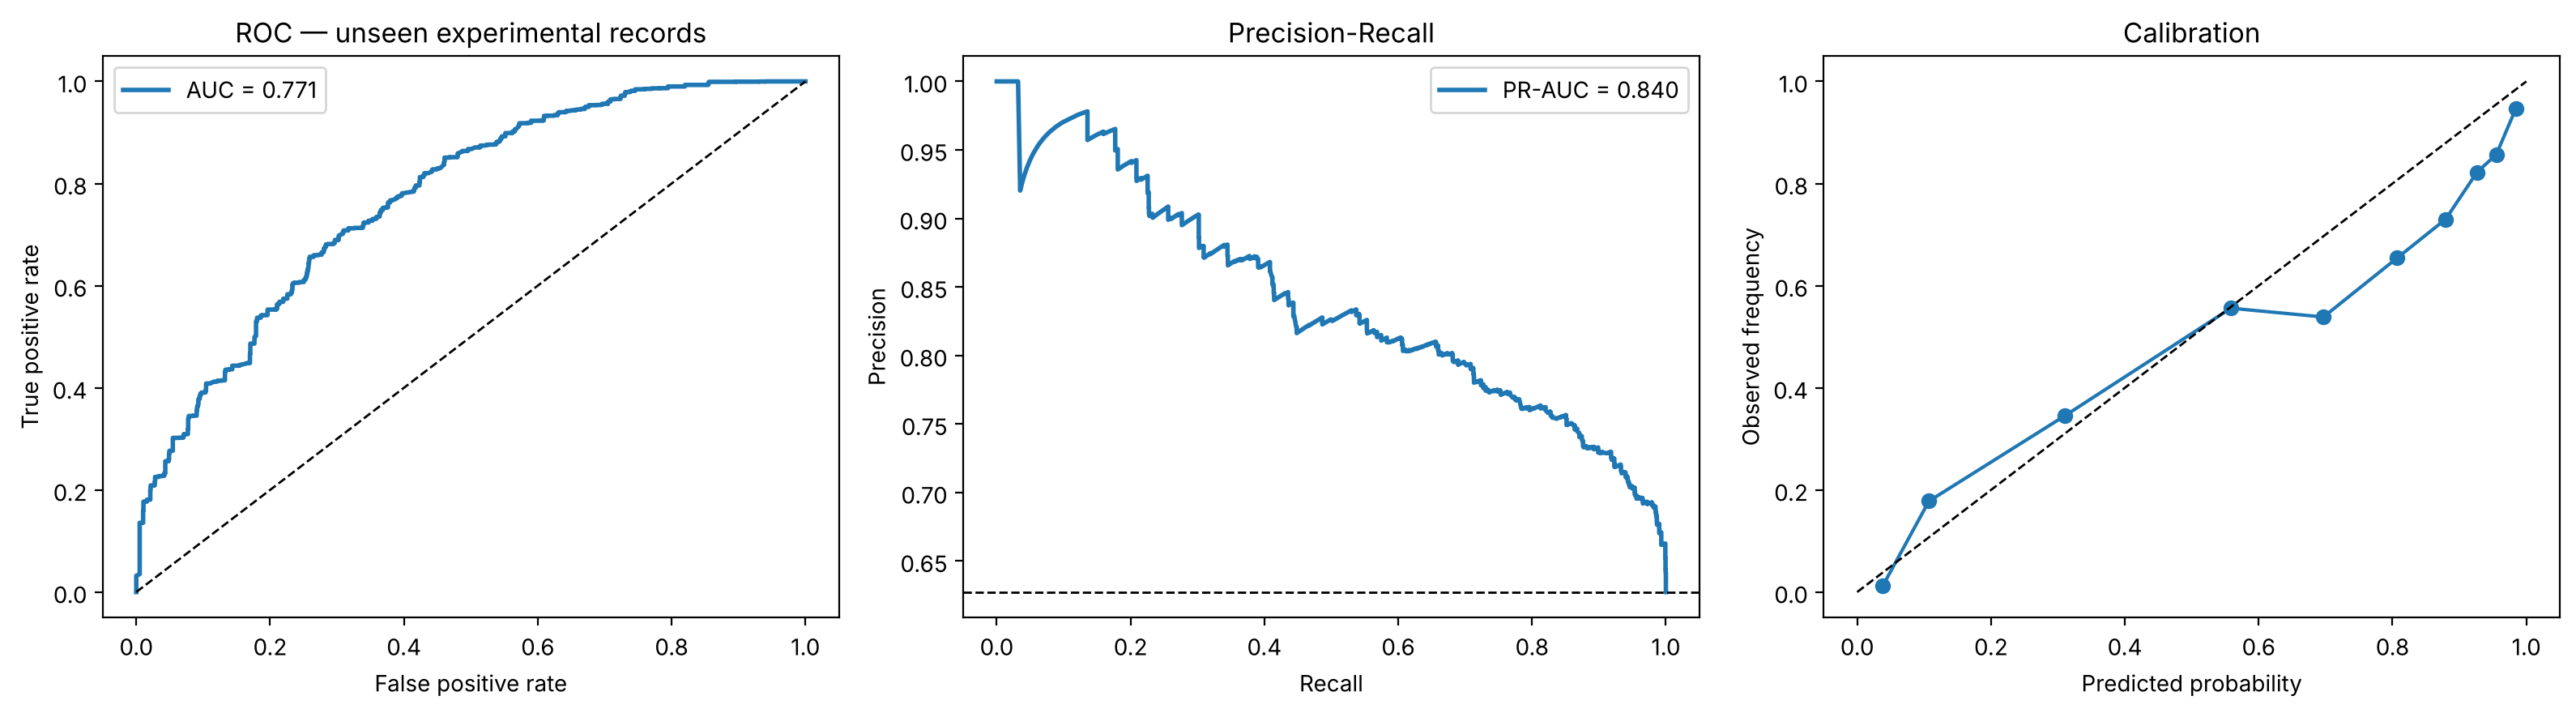

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(teA.Label, p, sample_weight=w)
ax[0].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(teA.Label, p, sample_weight=w):.3f}")
ax[0].plot([0, 1], [0, 1], 'k--', lw=1)
ax[0].set(xlabel="False positive rate", ylabel="True positive rate",
          title="ROC — unseen experimental records"); ax[0].legend()
pc, rc, _ = precision_recall_curve(teA.Label, p, sample_weight=w)
ax[1].plot(rc, pc, lw=2, label=f"PR-AUC = {average_precision_score(teA.Label, p, sample_weight=w):.3f}")
ax[1].axhline(np.average(teA.Label, weights=w), ls='--', c='k', lw=1)
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall"); ax[1].legend()
fr, mp = calibration_curve(teA.Label, p, n_bins=10, strategy="quantile")
ax[2].plot(mp, fr, 'o-'); ax[2].plot([0, 1], [0, 1], 'k--', lw=1)
ax[2].set(xlabel="Predicted probability", ylabel="Observed frequency", title="Calibration")
plt.tight_layout(); plt.savefig("figures_regimeA.png", dpi=150); plt.show()

top 10 features by mean |SHAP|:
  protein_conc_uM            0.4338  [env]
  NaCl_mM                    0.3990  [env]
  PEG_3k_6k_pct              0.3179  [env]
  temperature_C              0.3132  [env]
  LCR_length                 0.2445  [seq]
  PEG_8k_20k_pct             0.2378  [env]
  AA_K_frac                  0.2230  [seq]
  AA_R_frac                  0.2005  [seq]
  AA_N_frac                  0.1895  [seq]
  pH                         0.1622  [env]


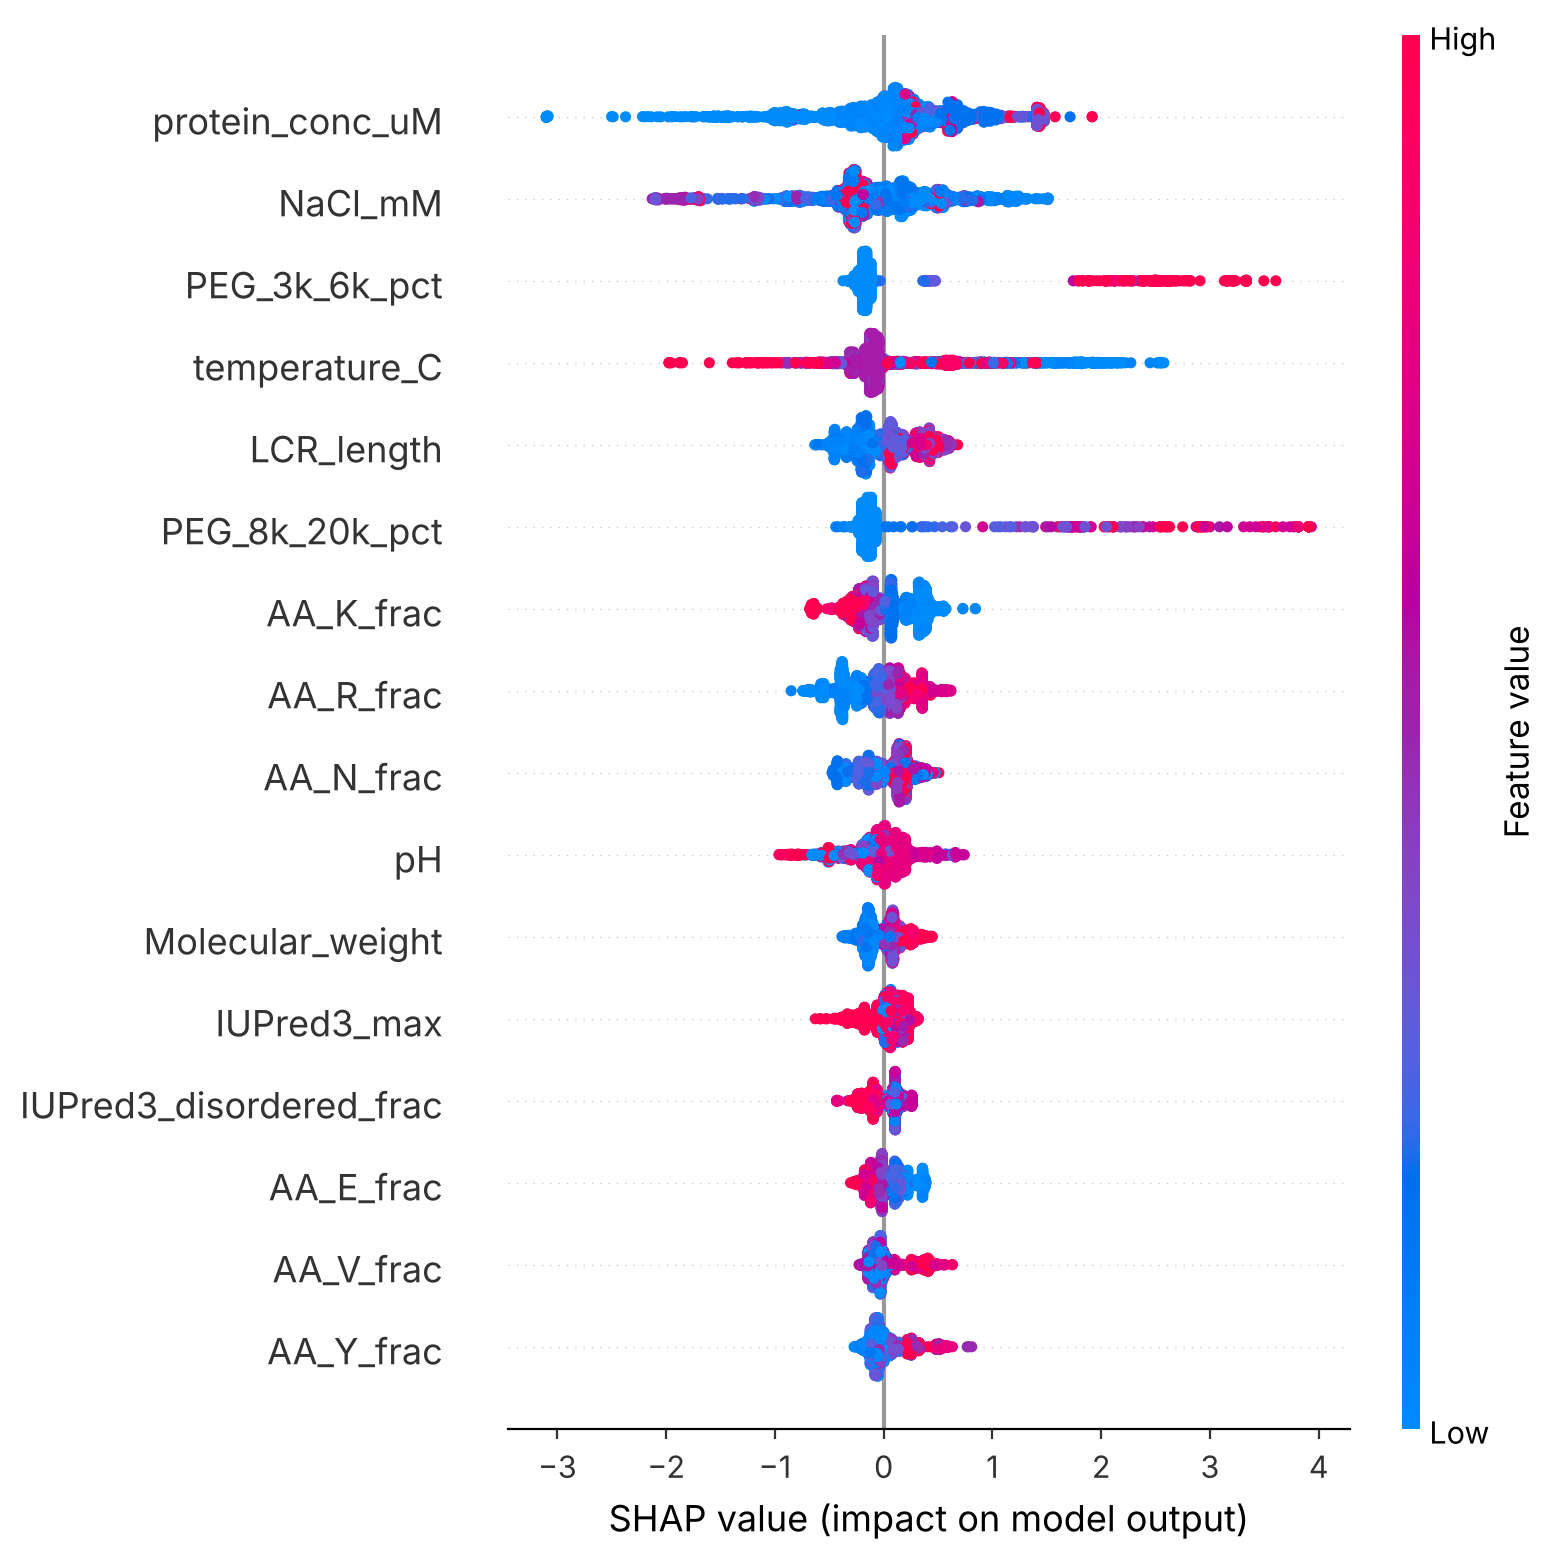

In [ ]:
sv = shap.TreeExplainer(model).shap_values(teA[COLS])
imp = pd.Series(np.abs(sv).mean(0), index=COLS).sort_values(ascending=False)
print("top 10 features by mean |SHAP|:")
for k, v in imp.head(10).items():
    print(f"  {k:26s} {v:.4f}  [{'env' if k in ENV else 'seq'}]")
imp.to_csv("shap_importance_regimeA.csv")

plt.figure(); shap.summary_plot(sv, teA[COLS], max_display=16, show=False)
plt.tight_layout(); plt.savefig("shap_regimeA.png", dpi=150); plt.show()

### Summary

| Regime | ROC-AUC | Accuracy |
|---|---|---|
| A — new conditions, known protein | **0.771** (held-out) | **75.9%** |
| B — new protein, homologs allowed | 0.600 | 57.0% |
| C — new protein family | 0.621 | 54.2% |
| *(random row split — invalid)* | *0.853* | — |

Regime A is well calibrated (Brier 0.172 vs 0.246 baseline) and its probabilities can be used
directly as condition-specific LLPS propensities. The gap to regimes B and C quantifies how much
of a naive 0.85 comes from memorizing proteins across folds.